<a href="https://colab.research.google.com/github/Hackathon-Group-F/Hackathon/blob/main/Hackathon_Group_F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Hackathon Group F

### Step 1: Data Exploration

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, log_loss
from sklearn.svm import SVC

In [2]:
# Loading Dataset
# Direct raw GitHub URLs
base_url = "https://raw.githubusercontent.com/Hackathon-Group-F/Hackathon/main/"

train = pd.read_csv(base_url + "dataset_A_training.csv")
test = pd.read_csv(base_url + "dataset_A_testing.csv")
example_sub = pd.read_csv(base_url + "dataset_A_example_submission.csv")

# Quick verification check
print("Successfully loaded datasets!")
print(f"Training set:   {train.shape[0]} rows, {train.shape[1]} columns")
print(f"Testing set:    {test.shape[0]} rows, {test.shape[1]} columns")
print(f"Example sub:    {example_sub.shape[0]} rows, {example_sub.shape[1]} columns")

# Inspect
train.head()

Successfully loaded datasets!
Training set:   4756 rows, 31 columns
Testing set:    4749 rows, 30 columns
Example sub:    4749 rows, 2 columns


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


In [3]:
print("="*60)
print("1. TARGET CLASS DISTRIBUTION")
print("="*60)
target_counts = train['seasonal_vaccine'].value_counts()
target_pct = (train['seasonal_vaccine'].value_counts(normalize=True) * 100).round(2)
target_summary = pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct})
print(target_summary)

print("\n" + "="*60)
print("2. MISSING VALUES COMPARISON (TRAIN vs TEST)")
print("="*60)
missing_train = train.isnull().sum()
missing_train_pct = (missing_train / len(train) * 100).round(2)
missing_test = test.isnull().sum()
missing_test_pct = (missing_test / len(test) * 100).round(2)

missing_df = pd.DataFrame({
    'Train Missing': missing_train,
    'Train %': missing_train_pct,
    'Test Missing': missing_test,
    'Test %': missing_test_pct
}).dropna(subset=['Train Missing'])

print(missing_df[missing_df['Train %'] > 0].sort_values(by='Train %', ascending=False))

print("\n" + "="*60)
print("3. CLINICAL RISK PROFILE (Drivers for $18,500 Hospitalisation Cost)")
print("="*60)
print("\nAge Group Breakdown:")
print(train.groupby('age_group')['seasonal_vaccine'].agg(['count', 'mean']).rename(columns={'mean': 'Vax_Rate'}))

print("\nChronic Conditions Breakdown:")
print(train.groupby('number_chronic_med_conditions')['seasonal_vaccine'].agg(['count', 'mean']).rename(columns={'mean': 'Vax_Rate'}))

1. TARGET CLASS DISTRIBUTION
                  Count  Percentage (%)
seasonal_vaccine                       
1                  2551           53.64
0                  2205           46.36

2. MISSING VALUES COMPARISON (TRAIN vs TEST)
                             Train Missing  Train %  Test Missing  Test %
employment_sector                     2314    48.65        2405.0   50.64
health_insurance                      1925    40.48        1982.0   41.74
income_poverty                         790    16.61         797.0   16.78
rent_or_own                            381     8.01         379.0    7.98
doctor_recc_seasonal                   321     6.75         345.0    7.26
education                              270     5.68         269.0    5.66
employment_status                      269     5.66         277.0    5.83
marital_status                         265     5.57         269.0    5.66
child_under_6_months                   152     3.20         155.0    3.26
health_worker            

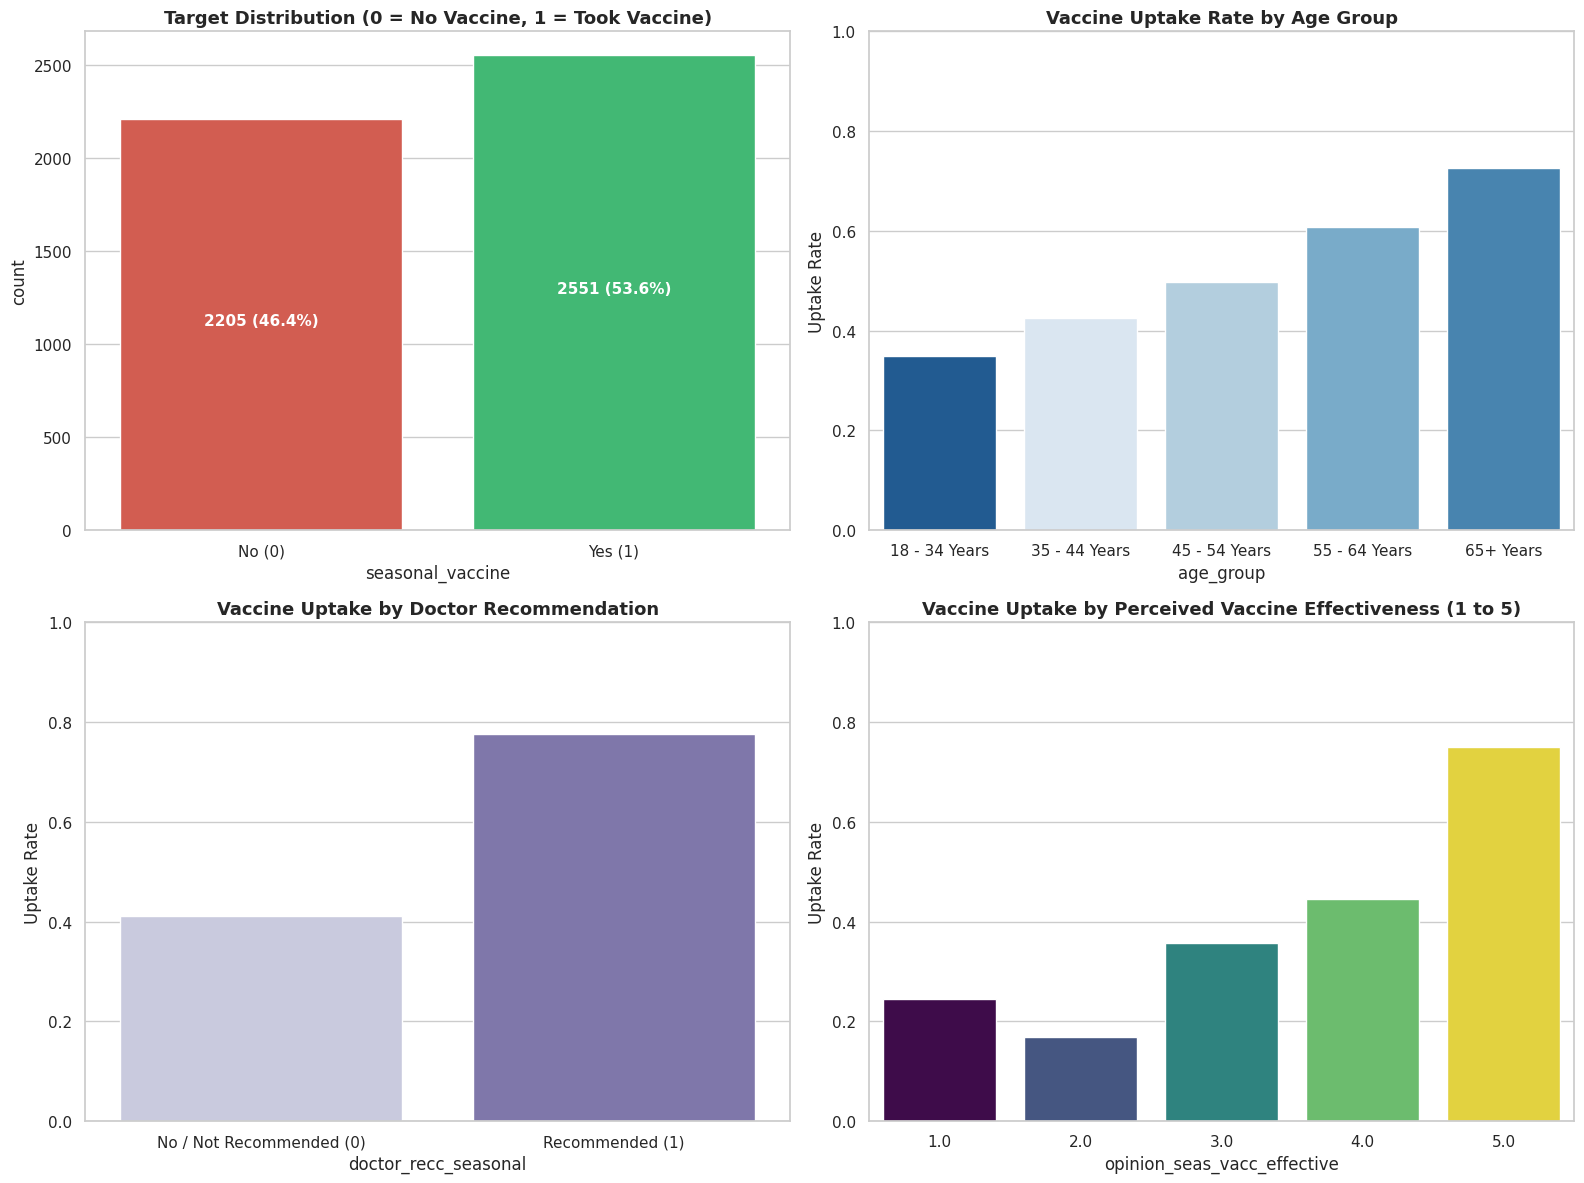

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Target Distribution
sns.countplot(x='seasonal_vaccine', hue='seasonal_vaccine', data=train, ax=axes[0, 0], palette=['#e74c3c', '#2ecc71'], legend=False)
axes[0, 0].set_title('Target Distribution (0 = No Vaccine, 1 = Took Vaccine)', fontsize=13, fontweight='bold')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(['No (0)', 'Yes (1)'])
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())} ({p.get_height()/len(train)*100:.1f}%)',
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', color='white', fontweight='bold', fontsize=11)

# 2. Vaccine Uptake by Age Group
age_order = ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years']
sns.barplot(x='age_group', y='seasonal_vaccine', hue='age_group', data=train, order=age_order, ax=axes[0, 1], palette='Blues_r', errorbar=None, legend=False)
axes[0, 1].set_title('Vaccine Uptake Rate by Age Group', fontsize=13, fontweight='bold')
axes[0, 1].set_ylabel('Uptake Rate')
axes[0, 1].set_ylim(0, 1)

# 3. Doctor Recommendation Impact
sns.barplot(x='doctor_recc_seasonal', y='seasonal_vaccine', hue='doctor_recc_seasonal', data=train, ax=axes[1, 0], palette='Purples', errorbar=None, legend=False)
axes[1, 0].set_title('Vaccine Uptake by Doctor Recommendation', fontsize=13, fontweight='bold')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(['No / Not Recommended (0)', 'Recommended (1)'])
axes[1, 0].set_ylabel('Uptake Rate')
axes[1, 0].set_ylim(0, 1)

# 4. Perceived Vaccine Effectiveness vs Uptake
sns.barplot(x='opinion_seas_vacc_effective', y='seasonal_vaccine', hue='opinion_seas_vacc_effective', data=train, ax=axes[1, 1], palette='viridis', errorbar=None, legend=False)
axes[1, 1].set_title('Vaccine Uptake by Perceived Vaccine Effectiveness (1 to 5)', fontsize=13, fontweight='bold')
axes[1, 1].set_ylabel('Uptake Rate')
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

### Step 2: Pre-processing

In [5]:
# -------------------------------------------------------------
# 1. SEPARATE TARGET AND IDENTIFIERS
# -------------------------------------------------------------
# Extract target vector and IDs
y_train = train['seasonal_vaccine'].astype(int)
train_ids = train['respondent_id']
test_ids = test['respondent_id']

# Feature matrices (exclude IDs and target)
X_train = train.drop(columns=['respondent_id', 'seasonal_vaccine']).copy()
X_test = test.drop(columns=['respondent_id']).copy()

# -------------------------------------------------------------
# 2. DEFINE FEATURE GROUPS
# -------------------------------------------------------------
cat_cols = [
    'age_group', 'education', 'race', 'sex', 'income_poverty',
    'marital_status', 'rent_or_own', 'employment_status',
    'census_msa', 'employment_sector'
]

binary_cols = [
    'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
    'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
    'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months',
    'health_worker', 'health_insurance'
]

ordinal_cols = [
    'flu_concern', 'flu_knowledge', 'opinion_seas_vacc_effective',
    'opinion_seas_risk', 'opinion_seas_sick_from_vacc'
]

count_cols = [
    'household_adults', 'household_children', 'number_chronic_med_conditions'
]

# -------------------------------------------------------------
# 3. IMPUTE MISSING VALUES (FIT ON TRAIN, TRANSFORM ON TEST)
# -------------------------------------------------------------
# A. Categoricals: label missing values as a distinct category ('Missing')
for col in cat_cols:
    X_train[col] = X_train[col].fillna('Missing').astype(str)
    X_test[col] = X_test[col].fillna('Missing').astype(str)

# B. Binary features: fill missing values with 0.0 (absence of condition/action)
for col in binary_cols:
    X_train[col] = X_train[col].fillna(0.0).astype(float)
    X_test[col] = X_test[col].fillna(0.0).astype(float)

# C. Ordinal ratings: fill missing values with median from the training set
for col in ordinal_cols:
    med_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(med_val).astype(float)
    X_test[col] = X_test[col].fillna(med_val).astype(float)

# D. Count features: fill missing values with mode from the training set
for col in count_cols:
    mode_val = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_val).astype(float)
    X_test[col] = X_test[col].fillna(mode_val).astype(float)

# -------------------------------------------------------------
# 4. ONE-HOT ENCODING & FEATURE ALIGNMENT
# -------------------------------------------------------------
X_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

# Ensure train and test share exact identical columns in identical order
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Convert all boolean dummy indicators to integers (0/1)
X_train_encoded = X_train_encoded.astype(float)
X_test_encoded = X_test_encoded.astype(float)

# -------------------------------------------------------------
# 5. SANITY CHECK & VALIDATION
# -------------------------------------------------------------
print("="*60)
print("PRE-PROCESSING VALIDATION")
print("="*60)
print(f"X_train shape: {X_train_encoded.shape} (rows, features)")
print(f"X_test shape:  {X_test_encoded.shape} (rows, features)")
print(f"y_train rows:  {len(y_train)}")
print(f"Remaining nulls in X_train: {X_train_encoded.isnull().sum().sum()}")
print(f"Remaining nulls in X_test:  {X_test_encoded.isnull().sum().sum()}")
print("Pre-processing successfully finished!")

PRE-PROCESSING VALIDATION
X_train shape: (4756, 64) (rows, features)
X_test shape:  (4749, 64) (rows, features)
y_train rows:  4756
Remaining nulls in X_train: 0
Remaining nulls in X_test:  0
Pre-processing successfully finished!


### Step 3: Modelling

In [9]:
# -------------------------------------------------------------
# 1. DEFINE FINE-TUNED CANDIDATE MODEL POOL (10 CONFIGURATIONS)
# -------------------------------------------------------------
from sklearn.svm import SVC

candidate_models = {
    # Linear Models (varying L2 regularization strength C)
    'LogReg (C=0.1, L2)': make_pipeline(
        StandardScaler(), LogisticRegression(C=0.1, penalty='l2', max_iter=1000, random_state=42)
    ),
    'LogReg (C=1.0, L2)': make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0, penalty='l2', max_iter=1000, random_state=42)
    ),

    # Support Vector Machine (RBF Kernel with Platt Scaling)
    'SVM (RBF, C=1.0)': make_pipeline(
        StandardScaler(), SVC(C=1.0, kernel='rbf', probability=True, random_state=42)
    ),

    # Bagging Ensembles (varying tree depth and leaf regularization)
    'Random Forest (depth=10)': RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),
    'Random Forest (depth=15)': RandomForestClassifier(
        n_estimators=400, max_depth=15, min_samples_leaf=3, random_state=42, n_jobs=-1
    ),
    'Extra Trees (depth=12)': ExtraTreesClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),

    # Boosting Ensembles (varying learning rate, depth, and L2 regularization)
    'GradBoost (lr=0.05, d=3)': GradientBoostingClassifier(
        n_estimators=250, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42
    ),
    'GradBoost (lr=0.03, d=4)': GradientBoostingClassifier(
        n_estimators=250, learning_rate=0.03, max_depth=4, subsample=0.8, random_state=42
    ),
    'HistGradBoost (lr=0.03, d=5)': HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.03, max_depth=5, l2_regularization=2.0, random_state=42
    ),

    # Neural Network (Multi-Layer Perceptron with L2 alpha penalty)
    'MLP Net (64, 32)': make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=0.1, max_iter=300, early_stopping=True, random_state=42)
    )
}

# -------------------------------------------------------------
# 2. TRAIN POOL ACROSS 5-FOLD STRATIFIED CROSS-VALIDATION
# -------------------------------------------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = {name: np.zeros(len(y_train)) for name in candidate_models}
test_preds = {name: np.zeros(len(X_test_encoded)) for name in candidate_models}
results_list = []

print("="*78)
print("TRAINING & TUNING CANDIDATE MODEL POOL (5-FOLD STRATIFIED CV)")
print("="*78)

for name, model in candidate_models.items():
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_encoded, y_train)):
        X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
        X_val, y_val = X_train_encoded.iloc[val_idx], y_train.iloc[val_idx]

        model.fit(X_tr, y_tr)
        oof_preds[name][val_idx] = model.predict_proba(X_val)[:, 1]
        test_preds[name] += model.predict_proba(X_test_encoded)[:, 1] / skf.n_splits

    probs = oof_preds[name]
    preds_bin = (probs >= 0.5).astype(int)

    auc = roc_auc_score(y_train, probs)
    acc = accuracy_score(y_train, preds_bin)
    f1 = f1_score(y_train, preds_bin)
    loss = log_loss(y_train, probs)

    results_list.append({
        'Model': name,
        'ROC-AUC': round(auc, 4),
        'Accuracy': round(acc, 4),
        'F1-Score': round(f1, 4),
        'Log-Loss': round(loss, 4)
    })
    print(f"✓ {name:<28} | ROC-AUC: {auc:.4f} | Acc: {acc:.4f} | LogLoss: {loss:.4f}")

# -------------------------------------------------------------
# 3. DYNAMICALLY BLEND TOP 3 & SELECT OVERALL TOP 5 MODELS
# -------------------------------------------------------------
standalone_df = pd.DataFrame(results_list).sort_values(by='ROC-AUC', ascending=False)
top_3_names = standalone_df.head(3)['Model'].tolist()

ens_name = 'Ensemble (Top 3 Tuned Blend)'
oof_preds[ens_name] = np.mean([oof_preds[m] for m in top_3_names], axis=0)
test_preds[ens_name] = np.mean([test_preds[m] for m in top_3_names], axis=0)

ens_probs = oof_preds[ens_name]
ens_bin = (ens_probs >= 0.5).astype(int)

results_list.append({
    'Model': ens_name,
    'ROC-AUC': round(roc_auc_score(y_train, ens_probs), 4),
    'Accuracy': round(accuracy_score(y_train, ens_bin), 4),
    'F1-Score': round(f1_score(y_train, ens_bin), 4),
    'Log-Loss': round(log_loss(y_train, ens_probs), 4)
})

# Sort full pool and extract Top 5
leaderboard_df = pd.DataFrame(results_list).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
leaderboard_df.index = leaderboard_df.index + 1  # Rank 1 to 11print("\n" + "="*78)

print("FULL CANDIDATE POOL LEADERBOARD (SORTED BY ROC-AUC)")
print("="*78)
print(leaderboard_df.to_string())
print("="*78)
print("All 11 models trained! Passing all models to Step 4 for Town Cost Evaluation.")

TRAINING & TUNING CANDIDATE MODEL POOL (5-FOLD STRATIFIED CV)
✓ LogReg (C=0.1, L2)           | ROC-AUC: 0.8493 | Acc: 0.7767 | LogLoss: 0.4844
✓ LogReg (C=1.0, L2)           | ROC-AUC: 0.8493 | Acc: 0.7763 | LogLoss: 0.4848
✓ SVM (RBF, C=1.0)             | ROC-AUC: 0.8404 | Acc: 0.7675 | LogLoss: 0.4939
✓ Random Forest (depth=10)     | ROC-AUC: 0.8459 | Acc: 0.7675 | LogLoss: 0.5036
✓ Random Forest (depth=15)     | ROC-AUC: 0.8462 | Acc: 0.7691 | LogLoss: 0.4965
✓ Extra Trees (depth=12)       | ROC-AUC: 0.8425 | Acc: 0.7687 | LogLoss: 0.5075
✓ GradBoost (lr=0.05, d=3)     | ROC-AUC: 0.8531 | Acc: 0.7782 | LogLoss: 0.4761
✓ GradBoost (lr=0.03, d=4)     | ROC-AUC: 0.8514 | Acc: 0.7754 | LogLoss: 0.4782
✓ HistGradBoost (lr=0.03, d=5) | ROC-AUC: 0.8482 | Acc: 0.7696 | LogLoss: 0.4828
✓ MLP Net (64, 32)             | ROC-AUC: 0.8374 | Acc: 0.7660 | LogLoss: 0.5007
FULL CANDIDATE POOL LEADERBOARD (SORTED BY ROC-AUC)
                           Model  ROC-AUC  Accuracy  F1-Score  Log-Loss
1   

### Step 4: Performance Analysis

In [10]:
# -------------------------------------------------------------
# 1. DEFINE HOSPITALISATION PROBABILITY MODEL
# -------------------------------------------------------------
# Baseline 100% infection probability assumed across the town
BASE_HOSP_RISK_BY_AGE = {
    '18 - 34 Years': 0.006,  # 0.6% base risk if infected
    '35 - 44 Years': 0.012,  # 1.2% base risk if infected
    '45 - 54 Years': 0.025,  # 2.5% base risk if infected
    '55 - 64 Years': 0.045,  # 4.5% base risk if infected
    '65+ Years': 0.095       # 9.5% base risk if infected
}

def estimate_hospitalisation_prob(age_group_series, chronic_cond_series, is_vaccinated):
    """
    Computes individual hospitalisation probability based on:
    1. Age group (0.6% to 9.5% base risk)
    2. Number of chronic medical conditions (+40% risk per condition, max 3.5x)
    3. Vaccination status (50% risk reduction if successfully vaccinated)
    """
    base_risk = age_group_series.map(BASE_HOSP_RISK_BY_AGE).fillna(0.025).values
    chronic_counts = chronic_cond_series.fillna(0).values
    chronic_multiplier = np.clip(1.0 + (chronic_counts * 0.4), 1.0, 3.5)

    unvax_prob = base_risk * chronic_multiplier

    if is_vaccinated:
        return np.clip(unvax_prob * 0.50, 0.0, 1.0)
    else:
        return np.clip(unvax_prob, 0.0, 1.0)

# Display a reference table showing how factors affect Hospitalisation Risk
sample_profiles = pd.DataFrame({
    'Age Group': ['18 - 34 Years', '45 - 54 Years', '65+ Years', '65+ Years'],
    'Chronic Conditions': [0, 1, 0, 2]
})
sample_profiles['Prob (Unvaccinated)'] = (estimate_hospitalisation_prob(
    sample_profiles['Age Group'], sample_profiles['Chronic Conditions'], False
) * 100).round(2).astype(str) + '%'
sample_profiles['Prob (Vaccinated)'] = (estimate_hospitalisation_prob(
    sample_profiles['Age Group'], sample_profiles['Chronic Conditions'], True
) * 100).round(2).astype(str) + '%'

print("="*85)
print("CLINICAL RISK FACTORS & HOSPITALISATION PROBABILITIES (100% Infection Assumed)")
print("="*85)
print(sample_profiles.to_string(index=False))

CLINICAL RISK FACTORS & HOSPITALISATION PROBABILITIES (100% Infection Assumed)
    Age Group  Chronic Conditions Prob (Unvaccinated) Prob (Vaccinated)
18 - 34 Years                   0                0.6%              0.3%
45 - 54 Years                   1                3.5%             1.75%
    65+ Years                   0                9.5%             4.75%
    65+ Years                   2               17.1%             8.55%
